# Module 3 · Notebook 1: The data and the model

Modules 1 and 2 built the engine and the transformer block. This module puts them together into a small GPT, trains it on one book, and makes it write.

Training takes hours on a CPU, so before spending them, this notebook answers one question: **is the model correct?** Every check here is cheap, and every one of them catches a bug that would otherwise only show up as "the loss looks a bit off".

| Step | What we do | Proof |
|---|---|---|
| 1 | **The data**: *The Adventures of Sherlock Holmes*, one book | — |
| 2 | **Characters → numbers**: the tokenizer | decode(encode(book)) == book |
| 3 | **Train / val split and batches** | — |
| 4 | **The embedding op**, the one new engine op | gradient check, and the same result as a one-hot matmul |
| 5 | **The GPT**: embeddings → 4 blocks → LayerNorm → output (tied to the input embedding) | — |
| 6 | **Check 1**: the loss before training | ≈ ln 88, and the numbers training has to beat |
| 7 | **Check 2**: gradient check of the whole model | every parameter, tied weights included |
| 8 | **Check 3**: no future leak through the whole model | earlier outputs change by exactly 0 |
| 9 | **Check 4**: overfit one batch | loss goes to ~0 |

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# notebooks/ -> 03-gpt/ -> llm-lab/. importing the Module 2 code also puts the Module 1 engine on the path
LAB = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(LAB / "02-attention"))
from transformer import block, init_block, layer_norm
from autograd import Tensor, cross_entropy
from gradcheck import gradcheck, TOL

print("python", sys.version.split()[0], "| numpy", np.__version__)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

python 3.12.15 | numpy 2.5.3


## Step 1: The data

One book from Project Gutenberg (public domain): *The Adventures of Sherlock Holmes*, eBook #1661. The file is downloaded once into `03-gpt/data/`.

Gutenberg adds a licence header and footer around the book. We keep only the text between the `*** START` and `*** END` markers.

In [2]:
DATA = LAB / "03-gpt" / "data" / "sherlock_raw.txt"
URL = "https://www.gutenberg.org/cache/epub/1661/pg1661.txt"

if not DATA.exists():
    import urllib.request
    DATA.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, DATA)

raw = DATA.read_text(encoding="utf-8-sig").replace("\r\n", "\n")
start = raw.find("*** START OF THE PROJECT GUTENBERG EBOOK")
end = raw.find("*** END OF THE PROJECT GUTENBERG EBOOK")
text = raw[raw.find("\n", start) + 1:end].strip()

print(f"raw file: {len(raw):,} characters, book only: {len(text):,} characters")
print("-" * 60)
print(text[3000:3600])

raw file: 581,601 characters, book only: 562,202 characters
------------------------------------------------------------
former friend and companion.

One night—it was on the twentieth of March, 1888—I was returning from a
journey to a patient (for I had now returned to civil practice), when
my way led me through Baker Street. As I passed the well-remembered
door, which must always be associated in my mind with my wooing, and
with the dark incidents of the Study in Scarlet, I was seized with a
keen desire to see Holmes again, and to know how he was employing his
extraordinary powers. His rooms were brilliantly lit, and, even as I
looked up, I saw his tall, spare figure pass twice in a dark silhouette
against the


About 562 thousand characters, about 105 thousand words. That is tiny by language-model standards (GPT-2 trained on ~40 GB of text), but enough for a small model to learn spelling, punctuation, dialogue and some of Doyle's style.

The lines are hard-wrapped at about 70 characters, like the original file. We leave that alone, so the model also has to learn where lines break.

## Step 2: Characters → numbers

The model works on integers, so we need a **tokenizer**. The simplest one: every distinct character is one token.

- **vocabulary** = the sorted set of characters in the book;
- **encode**: character → its index;
- **decode**: index → character.

Real GPTs use subword tokens (BPE), where one token is a common chunk like `" the"` or `"ing"`. That is a later module; character level keeps this one about the model and the training.

In [3]:
chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}

def encode(s):
    return np.array([stoi[c] for c in s], dtype=np.int64)

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

print("vocab size:", V)
print("vocab:", repr("".join(chars)))
print()
print("encode('Holmes') ->", encode("Holmes"))
print("decode(...)      ->", repr(decode(encode("Holmes"))))

data = encode(text)
assert decode(data) == text   # proof: the whole book survives the round trip
print(f"\nround trip on the whole book ({len(data):,} tokens): OK")

vocab size: 88
vocab: '\n !&(),-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZ_abcdefghijklmnopqrstuvwxyz£½àâæèéœ—‘’“”'

encode('Holmes') -> [29 63 60 61 53 67]
decode(...)      -> 'Holmes'

round trip on the whole book (562,202 tokens): OK


88 characters: letters, digits, punctuation, newline, and a few rare ones (`é`, `£`, `½`, curly quotes). The round trip over the full book is exact, so no information is lost before the model sees the text.

## Step 3: Train / val split and batches

The first 90% of the book is for training, the last 10% for **validation**: text the model never trains on. The val loss is the honest number. The train loss alone can go down just by memorising.

The split is one cut, not random pieces. A random split would put sentences from the same page into both halves, and the val loss would look better than it really is.

In [4]:
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print(f"train: {len(train_data):,} tokens   val: {len(val_data):,} tokens")
print("val starts with:", repr(decode(val_data[:120])))

train: 505,981 tokens   val: 56,221 tokens
val starts with: 'ul one. When I remembered that you had seen her at that\nwindow, and how she had fainted on seeing the coronet again, my\n'


A training example is a window of $T$ characters. The target is the same window shifted by one: at every position the model has to predict the **next** character.

So one window of $T = 128$ gives 128 predictions at once: predict character 2 from character 1, character 3 from characters 1–2, ..., character 129 from all 128. The causal mask from Module 2 is what makes this legal: position $t$ cannot see the answer at $t+1$.

In [5]:
def get_batch(data, B, T, rng):
    # B random windows of length T, and the same windows shifted by one as targets
    ix = rng.integers(0, len(data) - T, B)
    x = np.stack([data[i:i + T] for i in ix])
    y = np.stack([data[i + 1:i + T + 1] for i in ix])
    return x, y

x, y = get_batch(train_data, B=2, T=24, rng=np.random.default_rng(0))
print("x shape", x.shape, " y shape", y.shape)
print()
print("input :", repr(decode(x[0])))
print("target:", repr(decode(y[0])))
print()
for t in range(5):
    print(f"  context {decode(x[0, :t + 1])!r:12} -> next {decode(y[0, t:t + 1])!r}")

x shape (2, 24)  y shape (2, 24)

input : 'over for this last Londo'
target: 'ver for this last London'

  context 'o'          -> next 'v'
  context 'ov'         -> next 'e'
  context 'ove'        -> next 'r'
  context 'over'       -> next ' '
  context 'over '      -> next 'f'


## Step 4: The embedding op

The first layer of the model turns each token id into a learned vector: row `id` of a matrix $W_{te}$ of shape $(V, C)$. In NumPy the forward pass is one line, `W[idx]`.

The engine has no indexing op yet, so this is the **one new op** in this module. The forward is "pick rows". The backward is "add each incoming gradient into the row it came from":

- if `idx` contains the same token twice (it always does, `e` appears over 50,000 times), **both gradients must be added**;
- this is where the classic bug hides.

In [6]:
idx = np.array([1, 1, 1, 2])          # token 1 appears three times
g = np.ones((4, 3))                   # gradient coming in, one row per position

wrong = np.zeros((4, 3))
wrong[idx] += g                       # looks right, but repeated indices are written once, not added
right = np.zeros((4, 3))
np.add.at(right, idx, g)              # unbuffered: every occurrence is added

print("grad for row 1 should be 3 (token 1 was used three times)")
print("  W.grad[idx] += g      ->", wrong[1])
print("  np.add.at(W.grad, ...) ->", right[1])

grad for row 1 should be 3 (token 1 was used three times)
  W.grad[idx] += g      -> [1. 1. 1.]
  np.add.at(W.grad, ...) -> [3. 3. 3.]


`W.grad[idx] += g` reads all the rows first, adds, and then writes them back, so for a repeated index the last write wins and the other gradients are lost. No error, no NaN, the model still trains, just worse. `np.add.at` does the additions one by one.

Here is the op written both ways, and the gradient check from Module 1 run on each with repeated indices:

In [7]:
def embedding(weight, idx):
    # weight: (V, C) Tensor, idx: integer array of any shape -> (*idx.shape, C)
    out = Tensor(weight.data[idx], (weight,), "embedding")
    def _backward():
        np.add.at(weight.grad, idx, out.grad)
    out._backward = _backward
    return out

def embedding_buggy(weight, idx):
    out = Tensor(weight.data[idx], (weight,), "embedding")
    def _backward():
        weight.grad[idx] += out.grad
    out._backward = _backward
    return out

rng = np.random.default_rng(0)
W0 = rng.standard_normal((6, 4))
ids = np.array([[0, 3, 3, 5], [3, 1, 0, 3]])     # token 3 four times, token 0 twice

err_right = gradcheck(lambda t: embedding(t[0], ids), [W0])
err_buggy = gradcheck(lambda t: embedding_buggy(t[0], ids), [W0])
print(f"np.add.at version : rel error {err_right:.1e}  {'PASS' if err_right < TOL else 'FAIL'}")
print(f"W.grad[idx] += g  : rel error {err_buggy:.1e}  {'PASS' if err_buggy < TOL else 'FAIL'}")

np.add.at version : rel error 9.7e-11  PASS
W.grad[idx] += g  : rel error 3.9e-01  FAIL


The gradient check catches the bug right away, which is why it gets run on every new op.

A second proof: an embedding lookup is the same thing as multiplying a **one-hot** matrix by $W$ (row $i$ of the one-hot matrix has a single 1 at position `idx[i]`). The engine already has a matmul with a tested backward, so the two must agree exactly in the forward pass and to rounding error in the gradient. The lookup is just much cheaper: no $(N, V)$ matrix of zeros.

In [8]:
R = rng.standard_normal((2, 4, 4))             # random upstream gradient, like gradcheck does

a = Tensor(W0.copy())
(embedding(a, ids) * R).sum().backward()

b = Tensor(W0.copy())
onehot = np.eye(6)[ids]                         # (2, 4, 6)
(Tensor(onehot) @ b * R).sum().backward()

print("forward identical:", np.array_equal(embedding(Tensor(W0), ids).data, onehot @ W0))
print(f"max grad difference: {np.abs(a.grad - b.grad).max():.1e}")

forward identical: True
max grad difference: 2.2e-16


## Step 5: The GPT

The whole model, GPT-2 style:

1. **token embedding** $W_{te}$ $(V, C)$ + **learned position embedding** $W_{pe}$ $(T, C)$;
2. $L$ transformer blocks from Module 2 (pre-LN, multi-head causal attention, GELU MLP, residuals);
3. a final LayerNorm;
4. **output layer**: one score (logit) per character, $\text{logits} = h\, W_{te}^\top$.

Item 4 is **weight tying**: the output layer reuses the input embedding instead of having its own $(C, V)$ matrix. The vector that represents a character going in is also the vector that is matched against coming out. GPT-2 does this, and there it saves 38.6M of its 124M parameters. At character level the saving is small (88 × 128 ≈ 11K parameters), but it is also a good test for the engine: $W_{te}$ now gets gradients from two places, the lookup and the output matmul, and they have to add up.

Positions are learned embeddings, like GPT-2. RoPE from Module 2 would also work; one change at a time.

The size, chosen to give readable text in a few hours on a CPU:

| | |
|---|---|
| vocab $V$ | 88 |
| context $T$ | 128 characters |
| width $C$ | 128 |
| layers $L$ | 4 |
| heads | 4 (head size 32) |

All parameters live in one flat dict (`"wte"`, `"h0.Wq"`, ...), which makes the optimizer and saving checkpoints simple later.

In [9]:
def init_gpt(cfg, rng):
    V, T, C, L = cfg["V"], cfg["T"], cfg["C"], cfg["L"]
    p = {
        "wte": rng.standard_normal((V, C)) * 0.02,
        "wpe": rng.standard_normal((T, C)) * 0.02,
        "lnf_g": np.ones(C), "lnf_b": np.zeros(C),
    }
    for i in range(L):
        for k, v in init_block(C, rng).items():
            p[f"h{i}.{k}"] = v
    return p

def gpt(P, idx, cfg):
    # P: dict of Tensors, idx: (B, T) token ids -> logits (B, T, V)
    B, T = idx.shape
    assert T <= cfg["T"], "longer than the position table"
    x = embedding(P["wte"], idx) + embedding(P["wpe"], np.arange(T))
    for i in range(cfg["L"]):
        pre = f"h{i}."
        x = block(x, {k[len(pre):]: v for k, v in P.items() if k.startswith(pre)}, cfg["H"])
    x = layer_norm(x, P["lnf_g"], P["lnf_b"])
    return x @ P["wte"].transpose((1, 0))          # tied: the output layer is the input embedding

def loss_fn(P, x, y, cfg):
    logits = gpt(P, x, cfg)
    return cross_entropy(logits.reshape(-1, cfg["V"]), y.reshape(-1))

cfg = dict(V=V, T=128, C=128, L=4, H=4)
params = init_gpt(cfg, np.random.default_rng(0))
P = {k: Tensor(v) for k, v in params.items()}

n_block = sum(v.size for k, v in params.items() if k.startswith("h0."))
print(f"token embedding  {params['wte'].size:>9,}   (also the output layer)")
print(f"position embed.  {params['wpe'].size:>9,}")
print(f"per block        {n_block:>9,}   x {cfg['L']}")
print(f"final LayerNorm  {params['lnf_g'].size + params['lnf_b'].size:>9,}")
print(f"total            {sum(v.size for v in params.values()):>9,}")

token embedding     11,264   (also the output layer)
position embed.     16,384
per block          197,760   x 4
final LayerNorm        256
total              818,944


About 0.82M parameters, 97% of them in the blocks. GPT-2 small is 124M, so this is ~150× smaller.

## Step 6: Check 1, the loss before training

At init the model knows nothing, so it should give every character about the same probability $1/V$. The cross-entropy of a uniform guess is

$$-\ln\frac{1}{V} = \ln 88 = 4.477.$$

If the first loss is much higher, the init is **confidently wrong**: the logits are too large, and the first part of training is spent just undoing that. That is why $W_{te}$ starts at std 0.02 rather than 1: with the tied output, the logits are $h\,W_{te}^\top$, and their size scales with $W_{te}$.

In [10]:
x, y = get_batch(train_data, B=8, T=cfg["T"], rng=np.random.default_rng(1))
logits = gpt(P, x, cfg)
loss0 = cross_entropy(logits.reshape(-1, V), y.reshape(-1)).data
print(f"loss at init {loss0:.3f}   ln(V) = {np.log(V):.3f}   logit std {logits.data.std():.3f}")

loss at init 4.560   ln(V) = 4.477   logit std 0.224


Close to 4.477. It is a little above because the logits are small but not exactly 0 (std ~0.2), so the model starts out very slightly confident about random characters.

So what loss counts as good? Two simple models give the reference points, both measured on the **val** text:

- **unigram**: always predict the overall character frequencies (no context at all);
- **bigram**: predict from the previous character only (a table of counts, like the start of Karpathy's makemore).

A trained GPT has to beat the bigram by a clear margin, or it is not using its 128 characters of context.

In [11]:
counts1 = np.bincount(train_data, minlength=V) + 1.0          # +1 so rare characters don't get probability 0
p1 = counts1 / counts1.sum()
unigram = -np.log(p1[val_data]).mean()

counts2 = np.ones((V, V))
np.add.at(counts2, (train_data[:-1], train_data[1:]), 1)      # the duplicate-index problem again, add.at counts every pair
p2 = counts2 / counts2.sum(axis=1, keepdims=True)
bigram = -np.log(p2[val_data[:-1], val_data[1:]]).mean()

print(f"uniform guess   {np.log(V):.3f}")
print(f"unigram (val)   {unigram:.3f}")
print(f"bigram  (val)   {bigram:.3f}")

uniform guess   4.477
unigram (val)   3.103
bigram  (val)   2.433


These are the numbers to beat in notebook 2: uniform 4.48 → unigram → bigram → GPT.

## Step 7: Check 2, gradient check of the whole model

Module 2 checked one block. Here the whole GPT is checked end to end: both embeddings, every block, the final LayerNorm, the tied output layer and the cross-entropy, for **every parameter**. It has to be a tiny config, because the numerical gradient needs two forward passes per parameter.

In [12]:
tiny = dict(V=V, T=6, C=8, L=2, H=2)
tp = init_gpt(tiny, np.random.default_rng(2))
names = list(tp)
tx, ty = get_batch(train_data, B=2, T=6, rng=np.random.default_rng(3))

f = lambda ts: loss_fn(dict(zip(names, ts)), tx, ty, tiny)
n_tiny = sum(v.size for v in tp.values())
print(f"tiny GPT: {n_tiny:,} parameters in {len(names)} tensors")

err = gradcheck(f, [tp[k].copy() for k in names])
print(f"  real init (embeddings std 0.02): worst rel error {err:.1e}  {'PASS' if err < TOL else 'FAIL'}")

big = {k: (v / 0.02 if k in ("wte", "wpe") else v).copy() for k, v in tp.items()}
err = gradcheck(f, [big[k] for k in names])
print(f"  embeddings std 1               : worst rel error {err:.1e}  {'PASS' if err < TOL else 'FAIL'}")

tiny GPT: 2,448 parameters in 28 tensors
  real init (embeddings std 0.02): worst rel error 2.3e-07  PASS
  embeddings std 1               : worst rel error 6.8e-09  PASS


Both pass (tolerance 1e-6), and `gradcheck` reports the **worst** tensor, so every parameter, `wte` with its two gradient paths included, matches the numerical derivative.

Why is the first number ~100× worse than usual? Not a bug. The finite-difference estimate always has an absolute error of about $10^{-9}$ here (the rounding noise from Module 1's ε experiment). At the real init, the small embeddings make the gradients reaching the blocks tiny, around $10^{-2}$ to $10^{-3}$, so the same absolute noise is a bigger *relative* error. With std-1 embeddings the gradients are of order 1 and the error drops back to the usual ~1e-9. Checking a model where the gradients are not tiny is the stronger test.

## Step 8: Check 3, no future leak through the whole model

Module 2 showed one block cannot see the future. The full model adds embeddings, four blocks and a final LayerNorm, so the test is repeated end to end: change the **last** character of the input and compare the logits at every earlier position.

In [13]:
x1, _ = get_batch(val_data, B=2, T=cfg["T"], rng=np.random.default_rng(4))
x2 = x1.copy()
x2[:, -1] = (x2[:, -1] + 1) % V                 # change only the last character

l1 = gpt(P, x1, cfg).data
l2 = gpt(P, x2, cfg).data
print("max change at positions 0..T-2:", np.abs(l1[:, :-1] - l2[:, :-1]).max())
print("max change at the last position:", np.abs(l1[:, -1] - l2[:, -1]).max())

max change at positions 0..T-2: 0.0
max change at the last position: 0.23952125615921682


Exactly 0.0 at every earlier position, and a real change at the last one, the only position allowed to see that character.

## Step 9: Check 4, overfit one batch

The last check before real training: take **one** small batch and train on it over and over. A model with this many parameters must be able to memorise 128 characters almost perfectly. If it can't, something between the loss and the parameter update is broken: a missing gradient, a sign error, a parameter that never gets updated.

Plain SGD on a smaller config so it runs in seconds. The real optimizer (AdamW) is notebook 2.

loss: step 0 4.499  step 100 0.034  step 299 0.0151
next-character accuracy on the batch: 99.2%

batch row 0  : 'logical College of St. George’s,'
model's guess: 'logical College of St. George’s,'


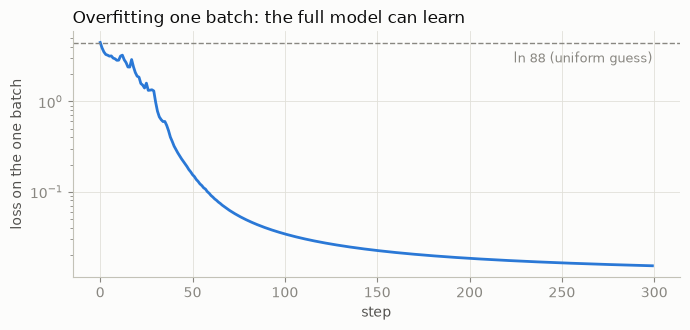

In [14]:
small = dict(V=V, T=32, C=64, L=2, H=4)
Ps = {k: Tensor(v) for k, v in init_gpt(small, np.random.default_rng(5)).items()}
bx, by = get_batch(train_data, B=4, T=32, rng=np.random.default_rng(6))

lr, losses = 0.3, []
for step in range(300):
    for t in Ps.values():
        t.grad = np.zeros_like(t.data)          # grads accumulate in the engine, so reset every step
    loss = loss_fn(Ps, bx, by, small)
    loss.backward()
    for t in Ps.values():
        t.data -= lr * t.grad
    losses.append(float(loss.data))

pred = gpt(Ps, bx, small).data.argmax(-1)
print(f"loss: step 0 {losses[0]:.3f}  step 100 {losses[100]:.3f}  step 299 {losses[-1]:.4f}")
print(f"next-character accuracy on the batch: {(pred == by).mean():.1%}")
print()
print("batch row 0  :", repr(decode(by[0])))
print("model's guess:", repr(decode(pred[0])))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(losses, color=SERIES[0])
ax.axhline(np.log(V), color=MUTED, ls="--", lw=1)
ax.text(299, np.log(V) * 0.8, "ln 88 (uniform guess)", color=MUTED, fontsize=9, ha="right", va="top")
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("loss on the one batch")
ax.set_title("Overfitting one batch: the full model can learn", loc="left")
plt.tight_layout()
plt.show()

The loss falls from ~4.5 to ~0.015 and the model gets about 99% of the batch's characters right, so gradients reach every part of the model and the updates go in the right direction. This says nothing about generalising, that is what the val loss is for.

## Summary

- **Data:** one book, 562K characters, 88-character vocabulary, 90/10 split with one cut.
- **One new op:** the embedding lookup. Its backward needs `np.add.at`; the obvious `W.grad[idx] += g` silently drops gradients for repeated tokens, and the gradient check catches it.
- **The model:** 0.82M parameters, 4 blocks from Module 2, output layer tied to the input embedding.
- **Four checks before training:** loss at init ≈ ln 88, the whole model passes the gradient check, no future leak, and it can overfit one batch.
- **Numbers to beat:** the unigram and bigram val losses from Step 6.

## Next: Notebook 2, training

AdamW written by hand, a warmup + cosine learning-rate schedule, gradient clipping, the real training run, and sampling text from the model (temperature, top-k, top-p).